In [1]:
import re
from collections import Counter
from urllib.parse import urlparse
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

# Target URL to audit (you can swap this for your Vercel/GitHub Pages URL anytime)
TARGET_URL = "https://www.python.org/"

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) SEO-Auditor-Bot/1.0"}
response = requests.get(TARGET_URL, headers=headers, timeout=10)
soup = BeautifulSoup(response.text, "html.parser")

print(f"Auditing: {TARGET_URL}")
print(f"HTTP Status: {response.status_code} | Response Time: {response.elapsed.total_seconds():.2f}s")

Auditing: https://www.python.org/
HTTP Status: 200 | Response Time: 0.89s


In [2]:
# 1. Title & Meta Description
title_tag = soup.title.string.strip() if soup.title and soup.title.string else ""
meta_desc_tag = soup.find("meta", attrs={"name": re.compile("^description$", re.I)})
meta_desc = meta_desc_tag["content"].strip() if meta_desc_tag and meta_desc_tag.get("content") else ""

# 2. Heading Tags (H1 - H3)
h1_tags = [h.get_text(strip=True) for h in soup.find_all("h1")]
h2_tags = [h.get_text(strip=True) for h in soup.find_all("h2")]
h3_tags = [h.get_text(strip=True) for h in soup.find_all("h3")]

# 3. Images & Missing Alt Attributes
images = soup.find_all("img")
missing_alt = [img.get("src", "no-src") for img in images if not img.get("alt") or not img.get("alt").strip()]

# 4. Internal vs External Links
domain = urlparse(TARGET_URL).netloc
internal_links, external_links = 0, 0
for a in soup.find_all("a", href=True):
    href = a["href"]
    if href.startswith("/") or domain in href:
        internal_links += 1
    elif href.startswith("http"):
        external_links += 1

# Build SEO Checklist Report
audit_data = [
    ["Page Title", title_tag[:60] + ("..." if len(title_tag) > 60 else ""), f"{len(title_tag)} chars", "PASS" if 30 <= len(title_tag) <= 65 else "WARN"],
    ["Meta Description", meta_desc[:60] + ("..." if len(meta_desc) > 60 else "Missing"), f"{len(meta_desc)} chars", "PASS" if 70 <= len(meta_desc) <= 160 else "WARN"],
    ["H1 Tag Count", ", ".join(h1_tags)[:60] or "None", f"{len(h1_tags)} H1s", "PASS" if len(h1_tags) == 1 else "WARN"],
    ["H2 / H3 Subheadings", f"{len(h2_tags)} H2s, {len(h3_tags)} H3s", f"{len(h2_tags) + len(h3_tags)} total", "PASS" if len(h2_tags) > 0 else "WARN"],
    ["Image Alt Coverage", f"{len(images) - len(missing_alt)}/{len(images)} have alt text", f"{len(missing_alt)} missing", "PASS" if len(missing_alt) == 0 else "WARN"],
    ["Link Structure", f"{internal_links} internal / {external_links} external", f"{internal_links + external_links} links", "PASS" if internal_links > 0 else "WARN"],
]

audit_df = pd.DataFrame(audit_data, columns=["SEO Check", "Extracted Value", "Metric", "Status"])
audit_df

,SEO Check,Extracted Value,Metric,Status
0,Page Title,Welcome to Python.org,21 chars,WARN
1,Meta Description,The official home of the Python Programming La...,52 chars,WARN
2,H1 Tag Count,"Functions Defined, All the Flow You’d Expect, ...",5 H1s,WARN
3,H2 / H3 Subheadings,"9 H2s, 0 H3s",9 total,PASS
4,Image Alt Coverage,1/1 have alt text,0 missing,PASS
5,Link Structure,127 internal / 78 external,205 links,PASS


In [3]:
# Remove script and style blocks before extracting visible text
for tag in soup(["script", "style", "noscript"]):
    tag.decompose()

text = soup.get_text(separator=" ").lower()
words = re.findall(r"\b[a-z]{3,}\b", text)

stop_words = {
    "the", "and", "for", "with", "that", "this", "from", "are", "was", "were",
    "have", "has", "had", "not", "but", "what", "all", "your", "can", "more",
    "about", "will", "into", "their", "out", "new", "get", "how", "use", "our"
}

filtered_words = [w for w in words if w not in stop_words]
total_words = len(filtered_words)

top_keywords = Counter(filtered_words).most_common(12)
kw_df = pd.DataFrame(top_keywords, columns=["Keyword", "Count"])
kw_df["Density_%"] = (kw_df["Count"] / total_words * 100).round(2)

print(f"Total Indexable Words (excluding stopwords): {total_words}")
kw_df

Total Indexable Words (excluding stopwords): 703


,Keyword,Count,Density_%
0,python,52,7.40
1,news,12,1.71
2,psf,11,1.56
3,events,11,1.56
4,community,10,1.42
5,docs,7,1.00
6,other,6,0.85
7,lists,6,0.85
8,software,6,0.85
9,print,6,0.85


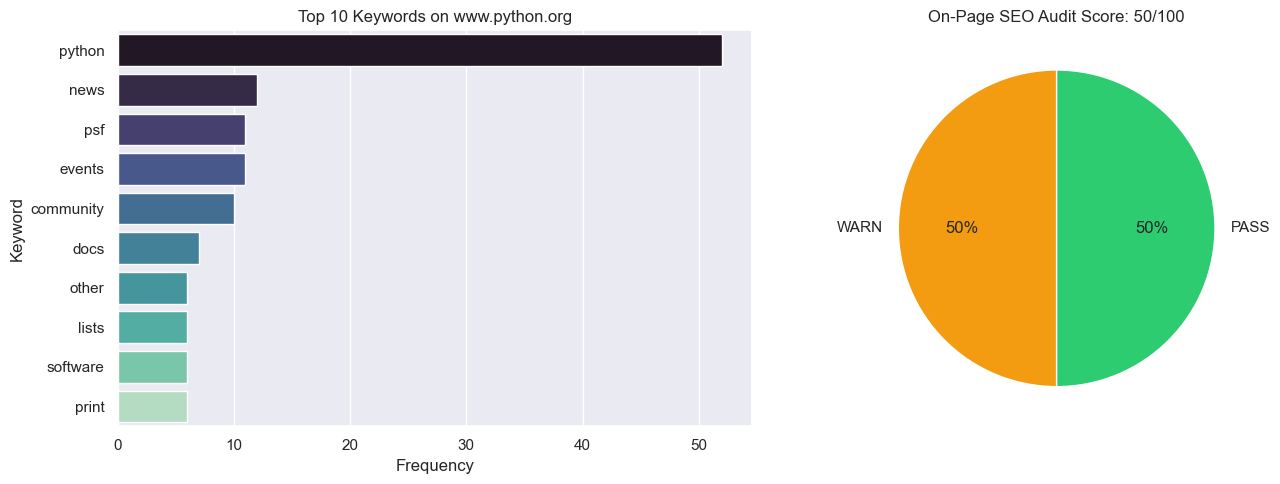

In [4]:
score = int((audit_df["Status"] == "PASS").mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Top 10 Keywords Bar Chart
sns.barplot(data=kw_df.head(10), x="Count", y="Keyword", hue="Keyword", palette="mako", legend=False, ax=axes[0])
axes[0].set_title(f"Top 10 Keywords on {domain}")
axes[0].set_xlabel("Frequency")

# Chart 2: SEO Pass vs Warning Breakdown
status_counts = audit_df["Status"].value_counts()
colors = ["#2ecc71" if s == "PASS" else "#f39c12" for s in status_counts.index]
axes[1].pie(status_counts, labels=status_counts.index, autopct="%1.0f%%", startangle=90, colors=colors)
axes[1].set_title(f"On-Page SEO Audit Score: {score}/100")

plt.tight_layout()
plt.show()